# Chapter 28 | Worked solutions

Time-Series Forecasting

All eleven exercises are solved here. We begin with what is known when a forecast is issued, build windows and patches by hand, and then check forecasts and evaluation protocols in Python.

Three plots make the main distinctions visible: asymmetric quantile loss, seasonal drift, and interval coverage versus width. All numerical results use small teaching fixtures, not performance measurements of TFT, PatchTST or a pretrained model.

## Setup

Run inside the companion repository with NumPy and Matplotlib. The examples run on CPU without model or dataset downloads.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "examples/ch28_time_series/model.py").exists())
sys.path.insert(0, str(repo_root))
from examples.ch28_time_series.model import (
    rolling_windows, seasonal_naive, fit_seasonal_drift,
    seasonal_drift, forecast_metrics,
)
plt.rcParams.update({"font.size": 11, "figure.figsize": (7, 3.6),
                     "axes.spines.top": False, "axes.spines.right": False})
print("Loaded local NumPy examples; no model downloads.")

Loaded local NumPy examples; no model downloads.


## 1. Separate what is known from what will arrive

The forecast is issued at Thursday's close. A future date does not automatically make an input unavailable: a published opening schedule can already be known. Conversely, a historical timestamp does not prove that a value has arrived.

| Value | Input type | Available at Thursday's close? |
| --- | --- | --- |
| Store size | Static covariate | Yes, if already recorded |
| Friday's scheduled opening hours | Known future covariate | Yes, use the schedule published by the origin |
| Thursday's sales | Past observation | Yes, assuming the daily total has arrived |
| Friday's measured foot traffic | Future observation | No |

The first three may enter the forecast under these assumptions. Preserve the schedule version that existed then. If Thursday's total is finalized later, use the latest available total or a predefined missing-value rule. The code illustrates the availability test with synthetic arrival times; it does not infer availability from the target date.

In [2]:
from datetime import datetime
issue = datetime(2026, 1, 8, 20)  # Thursday, 20:00
arrivals = {
    "store size": datetime(2026, 1, 1),
    "Friday schedule": datetime(2026, 1, 7),
    "Thursday sales": datetime(2026, 1, 8, 19, 59),
    "Friday measured traffic": datetime(2026, 1, 9, 20),
}
available = {name: arrival <= issue for name, arrival in arrivals.items()}
assert list(available.values()) == [True, True, True, False]
for name, allowed in available.items():
    print(f"{name}: {'available' if allowed else 'not yet available'}")

store size: available
Friday schedule: available
Thursday sales: available
Friday measured traffic: not yet available


## 2. Keep targets inside their split

The last training target must be at most 15. With three targets, the last training origin is therefore 13: its targets are 13, 14 and 15. Origins 14 and 15 cross the split and must be omitted. The first test origin is 16, whose history can legitimately include training-period observations.

| Window | Origin | Past indices | Target indices |
| --- | --- | --- | --- |
| Last training | 13 | 9, 10, 11, 12 | 13, 14, 15 |
| First test | 16 | 12, 13, 14, 15 | 16, 17, 18 |

For split boundary $b=16$, training origins satisfy $o+H\le b$ and test origins satisfy $o\ge b$. The final complete test origin is 21, with targets 21--23. Sharing past observations across windows is allowed; using a future target as an earlier input is not.

In [3]:
origins, past, targets = rolling_windows(np.arange(24), 4, 3)
training = origins + 3 <= 16
testing = origins >= 16
assert origins[training][-1] == 13 and origins[testing][0] == 16
assert origins[~(training | testing)].tolist() == [14, 15]
for origin in [13, 16]:
    row = np.flatnonzero(origins == origin).item()
    print(f"Origin {origin}: past {past[row]}, targets {targets[row]}")
print("Omitted crossing origins:", origins[~(training | testing)].tolist())

Origin 13: past [ 9. 10. 11. 12.], targets [13. 14. 15.]
Origin 16: past [12. 13. 14. 15.], targets [16. 17. 18.]
Omitted crossing origins: [14, 15]


## 3. Trace overlapping patches

The starts are 0, 2 and 4. Each patch contains three consecutive values.

| Patch | Indices | Values |
| --- | --- | --- |
| First | 0, 1, 2 | 4, 2, 6 |
| Second | 2, 3, 4 | 6, 1, 7 |
| Third | 4, 5, 6 | 7, 3, 8 |

The first two patches share index 2, value 6. The last two share index 4, value 7. Index 7, value 5, appears in no complete patch: a fourth patch would start at 6 and require index 8.

The formula gives $1+\lfloor(8-3)/2\rfloor=3$ patches. Dense attention has $3^2=9$ ordered query--key pairs per channel and head, including three self-pairs. Both directions between two different patches count. This is a pair count, not a measurement of total runtime. Padding or changing the stride would change the tokenization and must be stated.

In [4]:
values_for_patches = np.array([4, 2, 6, 1, 7, 3, 8, 5])
starts = list(range(0, len(values_for_patches)-3+1, 2))
index_rows = [list(range(start, start+3)) for start in starts]
patch_rows = np.stack([values_for_patches[row] for row in index_rows])
np.testing.assert_array_equal(patch_rows, [[4,2,6], [6,1,7], [7,3,8]])
unused = set(range(8)) - set(sum(index_rows, []))
assert unused == {7} and len(starts)**2 == 9
print("Patch rows:", patch_rows.tolist())
print("Shared indices:", [sorted(set(a) & set(b))
                          for a,b in zip(index_rows, index_rows[1:])])
print("Unused index/value:", [(i, int(values_for_patches[i])) for i in sorted(unused)])
print("Ordered pairs:", len(starts)**2)

Patch rows: [[4, 2, 6], [6, 1, 7], [7, 3, 8]]
Shared indices: [[2], [4]]
Unused index/value: [(7, 5)]
Ordered pairs: 9


## 4. Count interval hits

The actual value 6 lies on the upper endpoint of $[2,6]$ and counts as a hit. The value 8 lies above $[4,7]$ and misses. Coverage is $1/2=50\%$. Widths are 4 and 3, so mean width is $(4+3)/2=3.5$ target units.

For the quantile calculation, use residual $e=y-\widehat q$. With actual 10, forecast 8 gives $e=2$ and loss $0.9(2)=1.8$. Forecast 12 gives $e=-2$ and loss $(1-0.9)(2)=0.2$. Both absolute errors are 2; underprediction costs nine times as much for this high quantile.

The plot shows both sides of that penalty and compares it with the symmetric 0.5-quantile loss. A quantile loss value is not an interval coverage rate. A nominal 80% interval also does not promise that a two-observation sample will have exactly 80% hits.

In [5]:
actual_one = np.array([6, 8])
lower_one, upper_one = np.array([2, 4]), np.array([6, 7])
hits = (lower_one <= actual_one) & (actual_one <= upper_one)
assert hits.tolist() == [True, False]
assert hits.mean() == .5 and (upper_one-lower_one).mean() == 3.5
def pinball(actual, forecast, tau):
    error = np.asarray(actual) - np.asarray(forecast)
    return np.maximum(tau*error, (tau-1)*error)
losses = pinball(10, [8, 12], .9)
np.testing.assert_allclose(losses, [1.8, .2])
print("Coverage:", hits.mean(), "mean width:", (upper_one-lower_one).mean())
print("0.9-quantile losses:", losses.round(2).tolist())

Coverage: 0.5 mean width: 3.5
0.9-quantile losses: [1.8, 0.2]


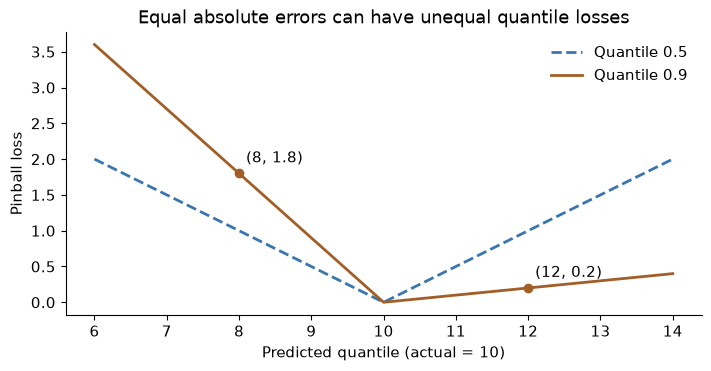

In [6]:
q = np.linspace(6, 14, 161)
fig, ax = plt.subplots(layout="constrained")
for tau, color, style in [(.5, "#3976af", "--"), (.9, "#a25e27", "-")]:
    ax.plot(q, pinball(10, q, tau), color=color, ls=style, lw=2,
            label=f"Quantile {tau}")
ax.scatter([8,12], losses, color="#a25e27", zorder=3)
for x, y in zip([8,12], losses):
    ax.annotate(f"({x}, {y:.1f})", (x,y), xytext=(5,8), textcoords="offset points")
ax.set(xlabel="Predicted quantile (actual = 10)", ylabel="Pinball loss",
       title="Equal absolute errors can have unequal quantile losses")
ax.legend(frameon=False)
display(fig)
plt.close(fig)

## 5. Inspect rolling windows

Imagine pausing the series just before the observation at index 3.
The three values already available are $(0,1,2)$. The next two
values, $(3,4)$, are the targets we will score against later.
The **forecast origin** is the index of the first unknown value,
so this window has origin 3. The past ends at index 2.

For an origin $t$, a lookback of $L$ uses indices $t-L$ through
$t-1$. A horizon of $H$ uses targets from $t$ through $t+H-1$.
In a series of length $N$ with indices $0$ through $N-1$, the
first past index must satisfy $t-L \ge 0$, and the last target
must satisfy $t+H-1 \le N-1$. Together these give
$L \le t \le N-H$. Here $L=3$, $H=2$, and $N=10$, so the valid
origins are 3 through 8.

In [7]:
from examples.ch28_time_series.model import rolling_windows

window_values = np.arange(10)
lookback, window_horizon = 3, 2
window_origins, past_rows, future_rows = rolling_windows(
    window_values, lookback, window_horizon
)

print("Origins", window_origins)
for row in (0, -1):
    print(
        f"Origin {window_origins[row]}  "
        f"past {past_rows[row]}  future {future_rows[row]}"
    )

Origins [3 4 5 6 7 8]
Origin 3  past [0. 1. 2.]  future [3. 4.]
Origin 8  past [5. 6. 7.]  future [8. 9.]


At origin 8 the past is $(5,6,7)$ and the targets are $(8,9)$.
The last target is $8+2-1=9$, the final index in the input.
Origin 9 would need targets at indices 9 and 10, so it would
have only one observed target. The rows here show values, which
happen to equal their indices because the series is $0$ through
$9$.

To check every row independently, slide a block of five values
through the input. Split each block after its first three values.
For example, the block $(1,2,3,4,5)$ gives past $(1,2,3)$ and
targets $(4,5)$ at origin 4.

In [8]:
expected_origins = [3, 4, 5, 6, 7, 8]
blocks = [window_values[start:start + 5] for start in range(6)]
expected_past = np.stack([block[:3] for block in blocks])
expected_future = np.stack([block[3:] for block in blocks])

np.testing.assert_array_equal(window_origins, expected_origins)
np.testing.assert_array_equal(past_rows, expected_past)
np.testing.assert_array_equal(future_rows, expected_future)
print("Checked the origins, past values, and targets of all six windows.")

Checked the origins, past values, and targets of all six windows.


## 6. Forecast beyond a season

The history $(2,5,3,6)$ contains two seasons of two values each.
A season is one full repetition of the pattern. The
seasonal-naive forecast copies the latest season, $(3,6)$.
It repeats that pair until it has five predictions, giving
$(3,6,3,6,3)$.

Drift is the estimated change from one season to the next. To
find it, compare each position in the second season with the
same position in the first. The differences are $3-2=1$ and
$6-5=1$, so their mean is $d=(1+1)/2=1$. This is one unit per
**season**, which lasts two steps here.

The first two forecasts are one season ahead of their matching
observations and receive $d$ each. Horizons 3 and 4 are two
seasons ahead and receive $2d$ each. Horizon 5 receives $3d$.

In [9]:
from examples.ch28_time_series.model import (
    fit_seasonal_drift,
    seasonal_drift,
    seasonal_naive,
)

season_history = np.array([2, 5, 3, 6])
period, season_horizon = 2, 5
naive_forecast = seasonal_naive(season_history, period, season_horizon)
fitted_drift = fit_seasonal_drift(season_history, period)
drift_forecast = seasonal_drift(
    season_history, period, season_horizon, fitted_drift
)

print(f"Fitted drift {fitted_drift:g} unit per season")
print("Horizon   Seasonal naive   Added drift   With drift")
for step, (base, forecast) in enumerate(
    zip(naive_forecast, drift_forecast), start=1
):
    print(f"{step:>7} {base:>16g} {forecast-base:>13g} {forecast:>12g}")

Fitted drift 1 unit per season
Horizon   Seasonal naive   Added drift   With drift
      1                3             1            4
      2                6             1            7
      3                3             2            5
      4                6             2            8
      5                3             3            6


**Horizon 3** is the first prediction to receive two drift
increments. The first forecast cycle gives $(3+1,6+1)=(4,7)$.
The third prediction returns to the first position of the
season, giving $3+2(1)=5$. The fourth gives $6+2(1)=8$, and
the fifth starts the third cycle with $3+3(1)=6$.

For a separate check of the drift forecast, extend the history
one step at a time. For each new value, take the value two
steps back and add one unit. The first two new values use the
observed pair $(3,6)$. For horizon 3, the value two steps
back is the first prediction, 4, so the new value is $4+1=5$.
This step-by-step calculation checks all five predictions.

In [10]:
expected_cycle = [3, 6, 3, 6, 3]
first_change = season_history[2] - season_history[0]
second_change = season_history[3] - season_history[1]
expected_drift = (first_change + second_change) / 2

extended = season_history.tolist()
for _ in range(season_horizon):
    extended.append(extended[-period] + expected_drift)
expected_forecast = extended[len(season_history):]

np.testing.assert_array_equal(naive_forecast, expected_cycle)
assert fitted_drift == expected_drift == 1
np.testing.assert_array_equal(drift_forecast, expected_forecast)
np.testing.assert_array_equal(
    drift_forecast - naive_forecast, [1, 1, 2, 2, 3]
)
print("Checked the cycle, fitted drift, and all five forecasts.")

Checked the cycle, fitted drift, and all five forecasts.


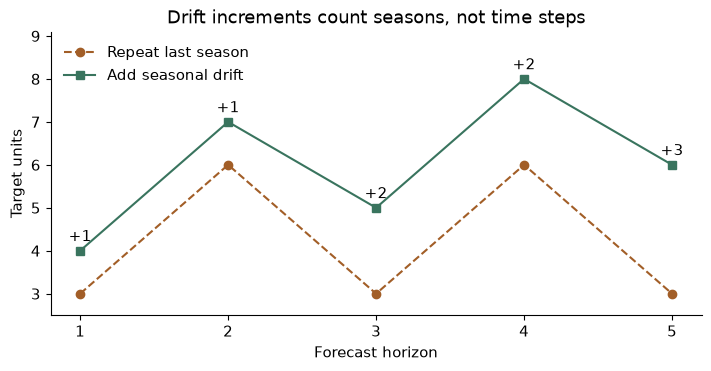

In [11]:
fig, ax = plt.subplots(layout="constrained")
h = np.arange(1, 6)
ax.plot(h, naive_forecast, "o--", color="#a25e27", label="Repeat last season")
ax.plot(h, drift_forecast, "s-", color="#39745e", label="Add seasonal drift")
for x, base, forecast in zip(h, naive_forecast, drift_forecast):
    ax.annotate(f"+{forecast-base:g}", (x, forecast),
                xytext=(0,7), textcoords="offset points", ha="center")
ax.set(xlabel="Forecast horizon", ylabel="Target units", xticks=h,
       ylim=(2.5,9.1), title="Drift increments count seasons, not time steps")
ax.legend(frameon=False, loc="upper left")
display(fig)
plt.close(fig)

## 7. Change what the baseline learned

At origin 24, the shop has observed values through index 23.
The chapter's seasonal-naive forecast copies the last observed
values for the three matching seasonal positions. It predicts
$(20,24,21)$, while the actual values are $(24,28,25)$. Each
prediction misses by four units. A model that learned a drift
of four would add four to each prediction.

Run the chapter's example as a module, as in the listing. The
notebook uses the current Python interpreter and reads the JSON
from a temporary directory. The mean absolute error (MAE) in
each column averages the absolute errors at that horizon
across all six test origins.

In [12]:
import json
import subprocess
from tempfile import TemporaryDirectory

with TemporaryDirectory() as temporary_directory:
    record_path = Path(temporary_directory) / "ch28.json"
    subprocess.run(
        [
            sys.executable,
            "-m", "examples.ch28_time_series.run_examples",
            "--output", str(record_path),
        ],
        cwd=repo_root,
        check=True,
        capture_output=True,
    )
    record = json.loads(record_path.read_text(encoding="utf-8"))

rolling = record["rolling"]
naive_mae = rolling["mae_seasonal_naive"]
fitted_mae = rolling["mae_seasonal_drift"]
assert rolling["fitted_drift"] == 4
assert naive_mae == [4, 4, 4]
assert fitted_mae == [0, 0, 0]

print("Fitted drift per season", rolling["fitted_drift"])
print("Horizons              1    2    3")
print("Seasonal-naive MAE  ", naive_mae)
print("Fitted-drift MAE    ", fitted_mae)

Fitted drift per season 4.0
Horizons              1    2    3
Seasonal-naive MAE   [4.0, 4.0, 4.0]
Fitted-drift MAE     [0.0, 0.0, 0.0]


The fixture adds a repeating four-position pattern to the time
index. Advancing four steps returns to the same pattern value
and raises the series by four. This explains why the fitted
drift is four and why it removes all the errors in this fixture.
That exact correction depends on how this toy series was made.

Now replace the fitted drift with zero. Origin $o$ is the first
unknown index, so `values[:origin]` ends at $o-1$. At later
origins, earlier test observations have arrived and can enter
the history. The three values at indices $o$, $o+1$, and $o+2$
are still withheld for scoring.

With period four, the first three steps copy indices $o-4$,
$o-3$, and $o-2$. They are all in the first forecast season, so
the drift model adds one increment to each. With a zero
increment, those three predictions stay equal to the
seasonal-naive predictions. Check both forecasts at every
origin against the values at the three source indices.

In [13]:
from examples.ch28_time_series.model import seasonal_drift
from examples.ch28_time_series.model import seasonal_naive
from examples.ch28_time_series.run_examples import series_example

values = series_example()
test_origins = rolling["test_origins"]
period, horizon = 4, 3
assert test_origins == list(range(24, 30))
assert rolling["period"] == period and rolling["horizon"] == horizon

zero_drift_forecasts = []
print("Origin  Seasonal naive        Zero drift")
for origin, recorded_naive in zip(test_origins, rolling["seasonal_naive"]):
    history = values[:origin]
    naive = seasonal_naive(history, period, horizon)
    zero_drift = seasonal_drift(history, period, horizon, drift=0)
    copied_values = values[origin - period:origin - period + horizon]
    np.testing.assert_array_equal(naive, copied_values)
    np.testing.assert_array_equal(naive, recorded_naive)
    np.testing.assert_array_equal(zero_drift, naive)
    zero_drift_forecasts.append(zero_drift)
    print(f"{origin:>6}  {str(naive.tolist()):<21}  {zero_drift.tolist()}")

targets = np.array(rolling["targets"])
errors = np.abs(targets - np.stack(zero_drift_forecasts))
zero_drift_mae = errors.mean(axis=0)
np.testing.assert_array_equal(zero_drift_mae, [4, 4, 4])
print("Zero-drift MAE", zero_drift_mae.tolist())

Origin  Seasonal naive        Zero drift
    24  [20.0, 24.0, 21.0]     [20.0, 24.0, 21.0]
    25  [24.0, 21.0, 25.0]     [24.0, 21.0, 25.0]
    26  [21.0, 25.0, 24.0]     [21.0, 25.0, 24.0]
    27  [25.0, 24.0, 28.0]     [25.0, 24.0, 28.0]
    28  [24.0, 28.0, 25.0]     [24.0, 28.0, 25.0]
    29  [28.0, 25.0, 29.0]     [28.0, 25.0, 29.0]
Zero-drift MAE [4.0, 4.0, 4.0]


All six forecasts with zero drift match seasonal naive entry for
entry. Both methods have MAE four at every horizon. Only the
fitted version adds the change the series makes between seasons.
The extra history at later origins updates the values the
model copies. The drift used in the original run stays fixed at
the value learned from the training prefix.

## 8. Compare interval widths

Imagine issuing the same point forecast with three different
margins. The point forecast can be equally accurate in every
case, while the wider interval catches an actual value that
fell outside the narrower one.

Use the chapter's two-origin fixture. The actual rows are
$(10,12,15)$ and $(11,13,14)$, and the prediction rows are
$(10,11,14)$ and $(10,13,12)$. The first column contains two
one-step forecasts, the second two two-step forecasts, and
the third two three-step forecasts. Comparing actual values to
point predictions gives absolute errors

$$
\begin{bmatrix} 0 & 1 & 1 \\ 1 & 0 & 2 \end{bmatrix}.
$$

Averaging down the columns gives MAE $(0.5,0.5,1.5)$.
For half-width $w$, subtract $w$ from each prediction to
get the lower endpoint and add $w$ to get the upper one.
Each interval then has width $2w$. Coverage at a horizon is
the fraction of its two actual values in their respective
intervals, including both endpoints. An actual value is
covered exactly when its absolute error is at most $w$.

| Half-width | Horizon 1 coverage | Horizon 2 coverage | Horizon 3 coverage | Mean width at every horizon |
| ---: | ---: | ---: | ---: | ---: |
| 0 | $1/2$ | $1/2$ | $0/2$ | 0 |
| 1 | $2/2$ | $2/2$ | $1/2$ | 2 |
| 2 | $2/2$ | $2/2$ | $2/2$ | 4 |

The intervals with half-width zero contain only exact
predictions. At half-width one, errors of one are covered
because the endpoints count. At half-width two, even the
largest error is covered. MAE depends only on the actual
values and point predictions, so we expect it to stay fixed.

In [14]:
from examples.ch28_time_series.model import forecast_metrics

actual = np.array([[10, 12, 15], [11, 13, 14]])
predicted = np.array([[10, 11, 14], [10, 13, 12]])
expected_mae = [0.5, 0.5, 1.5]
expected_coverage = [
    [0.5, 0.5, 0.0],
    [1.0, 1.0, 0.5],
    [1.0, 1.0, 1.0],
]
for half_width in (0, 1, 2):
    lower = predicted - half_width
    upper = predicted + half_width
    mae, coverage, mean_width = forecast_metrics(
        actual, predicted, lower, upper
    )
    np.testing.assert_array_equal(mae, expected_mae)
    np.testing.assert_array_equal(
        coverage, expected_coverage[half_width]
    )
    np.testing.assert_array_equal(mean_width, [2 * half_width] * 3)
    print(f"Half-width {half_width}")
    print("  Lower endpoints", lower.tolist())
    print("  Upper endpoints", upper.tolist())
    print("  MAE             ", mae.tolist())
    print("  Coverage        ", coverage.tolist())
    print("  Mean width      ", mean_width.tolist())

Half-width 0
  Lower endpoints [[10, 11, 14], [10, 13, 12]]
  Upper endpoints [[10, 11, 14], [10, 13, 12]]
  MAE              [0.5, 0.5, 1.5]
  Coverage         [0.5, 0.5, 0.0]
  Mean width       [0.0, 0.0, 0.0]
Half-width 1
  Lower endpoints [[9, 10, 13], [9, 12, 11]]
  Upper endpoints [[11, 12, 15], [11, 14, 13]]
  MAE              [0.5, 0.5, 1.5]
  Coverage         [1.0, 1.0, 0.5]
  Mean width       [2.0, 2.0, 2.0]
Half-width 2
  Lower endpoints [[8, 9, 12], [8, 11, 10]]
  Upper endpoints [[12, 13, 16], [12, 15, 14]]
  MAE              [0.5, 0.5, 1.5]
  Coverage         [1.0, 1.0, 1.0]
  Mean width       [4.0, 4.0, 4.0]


For the second origin at horizon three, the point prediction
is 12 and the actual value is 14. At half-width one, the upper
endpoint is 13 and the interval misses. At half-width two,
the upper endpoint is 14 and the interval hits. That change
brings coverage at horizon three from one hit out of two to
two hits out of two. The error for this same point prediction
stays at two units. The wider interval buys more coverage
at the cost of precision about where the outcome will fall.

Widening these intervals after inspecting the same outcomes is a sensitivity exercise. It cannot establish prospective 80% coverage. A real protocol would choose the interval rule using training or earlier calibration outcomes, issue new intervals, and score them only when their outcomes arrive. With two observations per horizon, possible observed coverages are only 0%, 50% and 100%.

The plot uses exactly the three rows of the table. MAE stays at (0.5, 0.5, 1.5) for every width; only the intervals change.

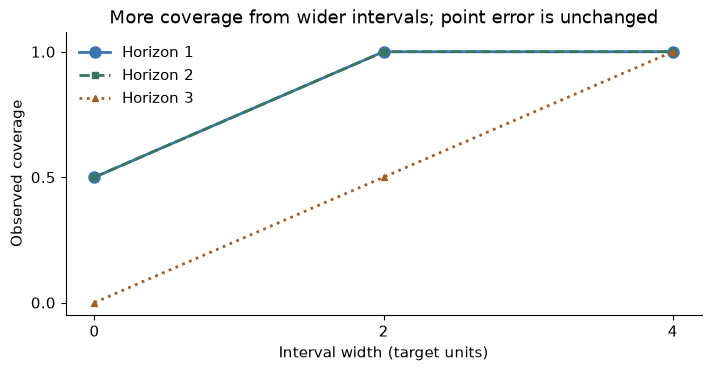

In [15]:
widths = np.array([0, 2, 4])
coverage_rows = np.array(expected_coverage)
fig, ax = plt.subplots(layout="constrained")
for h, (marker, style, color) in enumerate([
        ("o","-","#3976af"), ("s","--","#39745e"), ("^",":","#a25e27")]):
    ax.plot(widths, coverage_rows[:,h], marker=marker, ls=style, color=color,
            lw=2, markersize=8 if h==0 else 5, label=f"Horizon {h+1}")
ax.set(xlabel="Interval width (target units)", ylabel="Observed coverage",
       xticks=widths, yticks=[0,.5,1], ylim=(-.05,1.08),
       title="More coverage from wider intervals; point error is unchanged")
ax.legend(frameon=False)
display(fig)
plt.close(fig)

## 9. Audit feature availability

At origin $o$, suppose sales through $o-1$ have arrived. A centered seven-day average stored on row $o-1$ uses days $o-4$ through $o+2$. The last three days are precisely the withheld targets of a three-step forecast. A historical row label therefore hides future information.

Use a trailing average of days $o-7$ through $o-1$, ending earlier if records arrive with delay. Define a missing-history policy in advance. This origin-time summary can be reused for all horizons; computing a fresh trailing average at each future date would eventually require unknown sales.

For weather, preserve both issue time and arrival time, location and target date for each forecast version. At origin $o$, select the latest forecast for the requested date that had actually arrived by $o$. Keep actual measured weather in a separate field. An update issued on $o+1$ is too late for a forecast originally made at $o$, even if it predicts $o+2$. If historical forecasts are unavailable, do not substitute the later measurements; use a predefined missing-value rule or omit that feature.

The code perturbs all observations at and after one origin. The trailing feature stays unchanged, while the centered feature changes. This demonstrates leakage in this construction; passing one perturbation test alone would not audit a whole pipeline.

In [16]:
o = 10
sales = np.arange(24, dtype=float)
changed = sales.copy()
changed[o:] += 700
def trailing_at_origin(x):
    return x[o-7:o].mean()
def centered_at_last_past_row(x):
    return x[o-4:o+3].mean()
assert trailing_at_origin(sales) == trailing_at_origin(changed) == 6
assert centered_at_last_past_row(changed)-centered_at_last_past_row(sales) == 300
print("Trailing mean before/after future perturbation:",
      trailing_at_origin(sales), trailing_at_origin(changed))
print("Centered mean before/after:",
      centered_at_last_past_row(sales), centered_at_last_past_row(changed))

Trailing mean before/after future perturbation: 6.0 6.0
Centered mean before/after: 9.0 309.0


## 10. Choose a rolling protocol

Consider a daily series and a three-step horizon. Use days 0--167 for training, 168--195 for validation and 196--251 for test. A window belongs to a split only when all its targets lie inside it. During validation, replay the fixed and weekly-refit procedures in time order. Choose lookback, features and update settings there, then freeze those choices.

Before origin 196, fit both final systems on the same permitted training-plus-validation pool, with targets fully observed by then. This refit after model selection is part of the declared protocol. Test origins are 196--249: 54 forecasts per system. The last origin's targets are 249, 250 and 251. Give both models the same observed history, future calendar, and as-issued plans or weather forecasts; exclude future measured traffic and sales.

The fixed system retains its parameters and fitted transformations. The weekly system refits at origins 203, 210, 217, 224, 231, 238 and 245, using only targets that have arrived by each update. This gives seven refits after the initial fit. Recompute training-fitted transformations within the allowed pool at each refit. Both models may refresh their input history daily; this does not itself update their parameters. Earlier test outcomes may train later weekly refits under this protocol, but no issued forecast may be revised.

Compare paired errors at the same origins separately by horizon. The 162 forecast--target pairs contain only 56 distinct target days, so do not treat all pairs as independent replicates. Use time-aware uncertainty estimates. Report initial fit time, all seven update times, total update cost, prediction latency and hardware. State whether an update finishes before that day's forecast deadline; a late model update cannot support an on-time prediction retroactively.

In [17]:
test_origins_protocol = np.arange(196, 252-3+1)
refits = list(range(203, 250, 7))
assert len(test_origins_protocol) == 54
assert refits == [203, 210, 217, 224, 231, 238, 245]
target_days = test_origins_protocol[:,None] + np.arange(3)
assert target_days.size == 162 and len(np.unique(target_days)) == 56
for origin in refits:
    latest_complete_training_origin = origin - 3
    assert latest_complete_training_origin + 2 == origin - 1
print("Test origins:", test_origins_protocol[0], "through", test_origins_protocol[-1])
print("Weekly refits:", refits)
print("Forecast-target pairs:", target_days.size,
      "distinct target days:", len(np.unique(target_days)))

Test origins: 196 through 249
Weekly refits: [203, 210, 217, 224, 231, 238, 245]
Forecast-target pairs: 162 distinct target days: 56


## 11. Evaluate intervals under a shift

Let $d$ be the opening date and use a seven-day forecast window, comparing horizons one and seven on the same origins. A before-origin satisfies $o+6<d$; an after-origin satisfies $o\ge d$. Origins $d-6$ through $d-1$ straddle the opening and form a separate transition group. At $o=d-2$, horizon one targets an old-regime day but horizon seven targets $d+4$. Pooling that row into either main group would mix regimes.

Fix study lengths and weekday balance before examining scores. Fit the point model before the study. Use its forecasts on a distinct earlier calibration period to estimate the 10th and 90th percentiles of signed residuals $y-\widehat y$, separately by horizon. Every calibration outcome must arrive before the first evaluated forecast. Add those frozen offsets to future point predictions. This is one nominal 80% interval construction; estimated residual quantiles do not guarantee 80% coverage after a distribution shift.

Keep the model fitting and input-history policy fixed across the comparison. Save each issued point forecast and interval with its timestamp. For each horizon and regime, report hits, total forecasts, coverage and mean width. Retain transition rows as a separate result. With fixed additive offsets, width stays constant within a horizon: a coverage drop then means more misses at that same width. If adaptive calibration is studied, declare it as another procedure and update only from outcomes already available.

The synthetic calculation uses calibration residuals from -4 through 4 at horizon one and twice those values at horizon seven. NumPy's stated linear quantile convention yields offsets $(-3.2,3.2)$ and $(-6.4,6.4)$. Before-shift residuals cycle through -4 to 5 twice, giving 14/20 hits at each horizon. Shifting them by 4 at horizon one and 8 at horizon seven leaves 8/20 hits. Widths remain 6.4 and 12.8. These small constructed counts illustrate the scoring rules; they are not evidence about a delivery service.

Coverage here is marginal at each horizon. It does not measure whether every day in a seven-day path is covered at once. For example, independent daily 80% hits would give $0.8^7\approx21\%$ whole-path coverage; dependence changes that calculation.

In [18]:
opening = 100
origins_shift = np.arange(80, 120)
groups = np.where(origins_shift+6 < opening, "before",
                  np.where(origins_shift >= opening, "after", "transition"))
assert origins_shift[groups=="transition"].tolist() == list(range(94,100))
calibration = np.column_stack([np.arange(-4,5), 2*np.arange(-4,5)])
offsets = np.quantile(calibration, [.1,.9], axis=0, method="linear")
np.testing.assert_allclose(offsets, [[-3.2,-6.4], [3.2,6.4]])
before = np.column_stack([np.tile(np.arange(-4,6),2),
                          2*np.tile(np.arange(-4,6),2)])
after = before + [4,8]
for name, residuals, expected_hits in [("before",before,14), ("after",after,8)]:
    hits = (offsets[0] <= residuals) & (residuals <= offsets[1])
    np.testing.assert_array_equal(hits.sum(axis=0), [expected_hits]*2)
    print(name, "hits / 20:", hits.sum(axis=0).tolist(),
          "coverage:", hits.mean(axis=0).tolist())
print("Frozen widths:", (offsets[1]-offsets[0]).round(1).tolist())
print("Transition origins:", origins_shift[groups=="transition"].tolist())
print("Independent seven-day path illustration:", round(.8**7,4))

before hits / 20: [14, 14] coverage: [0.7, 0.7]
after hits / 20: [8, 8] coverage: [0.4, 0.4]
Frozen widths: [6.4, 12.8]
Transition origins: [94, 95, 96, 97, 98, 99]
Independent seven-day path illustration: 0.2097


## Checks and next steps

All eleven solutions connect an independent calculation to the chapter's functions or an explicitly specified evaluation design. The saved plots and outputs separate timing, point accuracy, interval coverage and update cost.

Try delaying every observation by one day. Redefine the available-history boundary before running the forecaster, and verify that changing unseen future values cannot change its issued prediction. This tests the availability contract, which matters before choosing a more complex architecture.